# Time-series clustering of household electricity consumption

**Author:** Abel Courchinoux

This notebook builds on the original assignment (household electricity data) and goes a bit further. The questions I work through are:

1. Compare k-means on **raw**, **row-standardized** and **energy-share** daily profiles.
2. Choose the number of clusters with the F-statistic (Calinski-Harabasz).
3. Interpret the clusters and compare the partitions.
4. Gaussian **kernel k-means**, and how sensitive it is to the bandwidth.
5. k-means on a small set of hand-made time-series features.
6. Conclude on the role of the representation / similarity measure.

The question behind all of this: **what should make two daily consumption curves "similar" - their level, their amplitude, the timing of the peaks, or their shape?**

In several sections I keep the algorithm fixed and only change the representation, so the effect of preprocessing is easy to see.

## 0. Data and setup

Data: UCI *Individual Household Electric Power Consumption* (minute-level measurements for one household, Dec 2006 - Nov 2010). I only use `Global_active_power`.

The file `household_power_consumption.txt` must be in the same folder as the notebook. The seed is fixed everywhere.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, pairwise_distances
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

SEED = 42
DATA_PATH = Path("household_power_consumption.txt")

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Loading the data and handling missing values

I'm stricter with missing values than in my first version. A plain `resample("h").mean()` gives an hourly value even if half of the minutes are missing, which is not what we want. So:

- an hour is kept only if all 60 minutes are observed;
- a day is kept only if all 24 hours are kept.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError("Put household_power_consumption.txt next to the notebook (or change DATA_PATH).")

data = pd.read_csv(DATA_PATH, sep=";", na_values="?", low_memory=False)
data["datetime"] = pd.to_datetime(data["Date"] + " " + data["Time"], format="%d/%m/%Y %H:%M:%S")
data["Global_active_power"] = pd.to_numeric(data["Global_active_power"], errors="coerce")
data = data.set_index("datetime").sort_index()[["Global_active_power"]]

print("Observations:", f"{len(data):,}")
print("Missing values:", f"{data['Global_active_power'].isna().sum():,}")
data.head()

Observations: 2,075,259
Missing values: 25,979


,Global_active_power
datetime,
2006-12-16 17:24:00,4.2160
2006-12-16 17:25:00,5.3600
2006-12-16 17:26:00,5.3740
2006-12-16 17:27:00,5.3880
2006-12-16 17:28:00,3.6660


In [3]:

power = data["Global_active_power"]
n_minutes = power.resample("h").count()
hourly = power.resample("h").mean()
hourly = hourly[n_minutes == 60]


tmp = hourly.to_frame("kwh")
tmp["date"] = tmp.index.normalize()
tmp["hour"] = tmp.index.hour

daily_profiles = tmp.pivot(index="date", columns="hour", values="kwh")
daily_profiles = daily_profiles.reindex(columns=range(24)).dropna()
daily_profiles.columns = [f"h{h:02d}" for h in range(24)]

print("Complete hours:", f"{len(hourly):,}")
print("Complete days:", f"{len(daily_profiles):,}")
daily_profiles.head()

Complete hours: 34,085
Complete days: 1,358


,h00,h01,h02,h03,h04,h05,h06,h07,h08,h09,h10,h11,h12,h13,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23
date,,,,,,,,,,,,,,,,,,,,,,,,
2006-12-17,1.8825,3.3494,1.5873,1.6622,2.2158,1.9967,1.3033,1.6200,1.8906,2.5491,3.6289,2.4710,1.9159,1.6608,2.0926,2.9854,3.3260,3.4068,3.6971,2.9084,3.3615,3.0408,1.5180,0.4377
2006-12-18,0.2764,0.3133,0.2845,0.3099,1.0263,0.2935,0.6100,2.4504,2.0821,1.6293,1.3096,1.5619,1.7561,1.6821,1.7330,1.7843,1.9493,2.1549,2.4025,2.6145,3.0506,2.1697,1.7388,1.5473
2006-12-19,0.8371,0.3530,0.3272,0.3083,0.3278,0.3067,0.7963,1.7856,3.8790,1.6178,0.4371,2.3216,0.4307,0.3005,0.3021,0.4214,1.3721,2.1115,2.2047,1.8421,2.9405,1.4429,0.7200,0.3837
2006-12-20,0.4598,0.2587,0.7844,0.3100,0.2890,0.2627,0.2836,1.5266,2.9176,1.3855,1.5103,2.8924,1.4210,1.4284,1.2949,0.2811,0.4684,0.5735,2.8368,3.2486,3.5755,3.6461,3.0590,2.3818
2006-12-22,0.2669,0.2720,0.2676,0.2739,0.2643,0.8068,0.4796,1.7232,2.7444,1.8963,1.3450,1.2526,1.2285,0.6719,0.8156,1.4516,1.5712,1.4968,2.6870,3.9382,3.5361,4.5487,3.0651,2.4192


Each row is now a full day and each column the same clock hour. Since every kept hour has 60 minute values, the hourly mean of the power (kW) is the energy in kWh over that hour. The data matrix is \(X \in \mathbb{R}^{n \times 24}\).

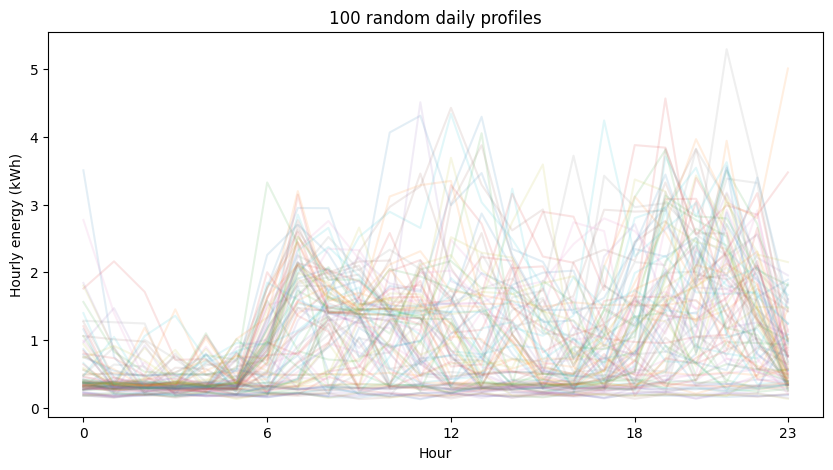

In [4]:
X_raw = daily_profiles.to_numpy(dtype=float)
dates = daily_profiles.index


rng = np.random.default_rng(SEED)
sample = rng.choice(len(X_raw), size=min(100, len(X_raw)), replace=False)

plt.figure(figsize=(10, 5))
for i in sample:
    plt.plot(X_raw[i], alpha=0.12)
plt.xlabel("Hour")
plt.ylabel("Hourly energy (kWh)")
plt.title("100 random daily profiles")
plt.xticks([0, 6, 12, 18, 23])
plt.show()

## 2. Baseline: five descriptive features

My first version described each day with five statistics: mean, min, max, standard deviation and median. I keep it as a baseline since it is compact and easy to read. The downside is that it ignores the order of the hours, so two days with peaks at different times can look the same.

In [5]:
baseline_features = pd.DataFrame({
    "mean": daily_profiles.mean(axis=1),
    "min": daily_profiles.min(axis=1),
    "max": daily_profiles.max(axis=1),
    "std": daily_profiles.std(axis=1),
    "median": daily_profiles.median(axis=1),
})

X_baseline = StandardScaler().fit_transform(baseline_features)
baseline_features.head()

,mean,min,max,std,median
date,,,,,
2006-12-17,2.3545,0.4377,3.6971,0.8628,2.1542
2006-12-18,1.5304,0.2764,3.0506,0.8178,1.7076
2006-12-19,1.1571,0.3005,3.8790,0.9934,0.7582
2006-12-20,1.5457,0.2587,3.6461,1.2045,1.4033
2006-12-22,1.6259,0.2643,4.5487,1.2490,1.3983


## 3. Helper functions

Calinski-Harabasz statistic:

\[
CH(K) = \frac{BSS/(K-1)}{WSS/(n-K)}
\]

The higher the between-cluster dispersion compared to the within-cluster one, the higher the score. I use it to pick \(K\) **within one representation**. Comparing CH values across different representations would not make sense, because the geometry is not the same.

In [6]:
def fit_kmeans(X, k):
    model = KMeans(n_clusters=k, n_init=30, max_iter=300, random_state=SEED)
    labels = model.fit_predict(X)
    return model, labels


def kmeans_grid(X, k_values=range(2, 10)):
    """Fit k-means for each K and return the scores table and the best K (max CH)."""
    tss = np.sum((X - X.mean(axis=0)) ** 2)
    rows = []
    for k in k_values:
        model, labels = fit_kmeans(X, k)
        wss = model.inertia_
        rows.append({
            "K": k,
            "WSS": wss,
            "BSS": tss - wss,
            "R2": (tss - wss) / tss,
            "Calinski_Harabasz": calinski_harabasz_score(X, labels),
        })
    scores = pd.DataFrame(rows).set_index("K")
    return scores, int(scores["Calinski_Harabasz"].idxmax())


def plot_selection_scores(scores, title):
    plt.figure(figsize=(7, 4))
    plt.plot(scores.index, scores["Calinski_Harabasz"], marker="o")
    plt.xlabel("Number of clusters K")
    plt.ylabel("Calinski-Harabasz score")
    plt.title(f"{title}: choice of K")
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(scores.index, scores["WSS"], marker="o")
    plt.xlabel("Number of clusters K")
    plt.ylabel("Within-cluster sum of squares")
    plt.title(f"{title}: elbow curve")
    plt.show()


def plot_cluster_profiles(X, labels, title, y_label="Hourly energy (kWh)"):
    clusters = np.unique(labels)
    fig, axes = plt.subplots(1, len(clusters), figsize=(5 * len(clusters), 4), sharex=True)
    axes = np.atleast_1d(axes)

    for ax, c in zip(axes, clusters):
        members = X[labels == c]
        ax.plot(members.T, alpha=0.08)
        ax.plot(members.mean(axis=0), linewidth=2.5, label="Cluster mean")
        ax.set_title(f"Cluster {c + 1} (n={len(members)})")
        ax.set_xticks([0, 6, 12, 18, 23])
        ax.set_xlabel("Hour")
        ax.legend()

    axes[0].set_ylabel(y_label)
    fig.suptitle(title, y=1.04)
    plt.tight_layout()
    plt.show()


def cluster_summary(X, labels, dates):
    dates = pd.DatetimeIndex(dates)
    rows = []
    for c in np.unique(labels):
        idx = labels == c
        mean_profile = X[idx].mean(axis=0)
        rows.append({
            "cluster": c + 1,
            "n_days": idx.sum(),
            "mean_hourly_energy": X[idx].mean(),
            "mean_daily_total": X[idx].sum(axis=1).mean(),
            "peak_hour_of_mean_profile": int(np.argmax(mean_profile)),
            "mean_peak_value": mean_profile.max(),
            "weekend_share": (dates[idx].dayofweek >= 5).mean(),
        })
    return pd.DataFrame(rows).set_index("cluster")


def ari_matrix(partitions):
    names = list(partitions)
    ari = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            ari.loc[a, b] = ari.loc[b, a] = adjusted_rand_score(partitions[a], partitions[b])
    return ari


def plot_ari_heatmap(ari, title="Adjusted Rand Index between partitions"):
    plt.figure(figsize=(7, 6))
    plt.imshow(ari.values, vmin=0, vmax=1)
    plt.colorbar(label="ARI")
    plt.xticks(range(len(ari)), ari.columns, rotation=45, ha="right")
    plt.yticks(range(len(ari)), ari.index)
    for i in range(len(ari)):
        for j in range(len(ari)):
            plt.text(j, i, f"{ari.iloc[i, j]:.2f}", ha="center", va="center")
    plt.title(title)
    plt.tight_layout()
    plt.show()

Baseline (5 features) - selected K: 2


,WSS,BSS,R2,Calinski_Harabasz
K,,,,
2,"3,921.0552","2,868.9448",0.4225,992.1577
3,"3,004.8182","3,785.1818",0.5575,853.4543
4,"2,245.4104","4,544.5896",0.6693,913.4743
5,"1,841.3778","4,948.6222",0.7288,909.0320
6,"1,612.5803","5,177.4197",0.7625,868.1579
7,"1,454.0859","5,335.9141",0.7858,826.3333
8,"1,317.0443","5,472.9557",0.8060,801.4146
9,"1,196.6250","5,593.3750",0.8238,788.2025


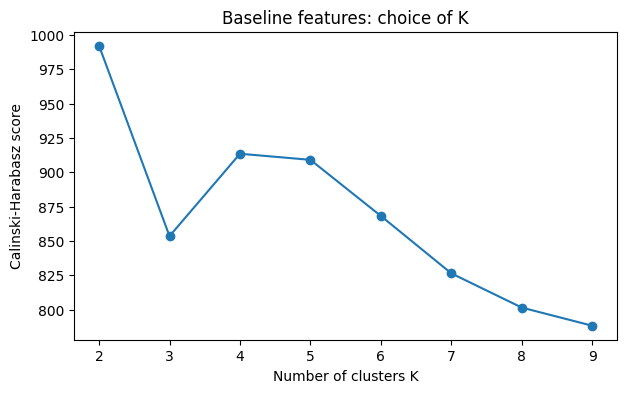

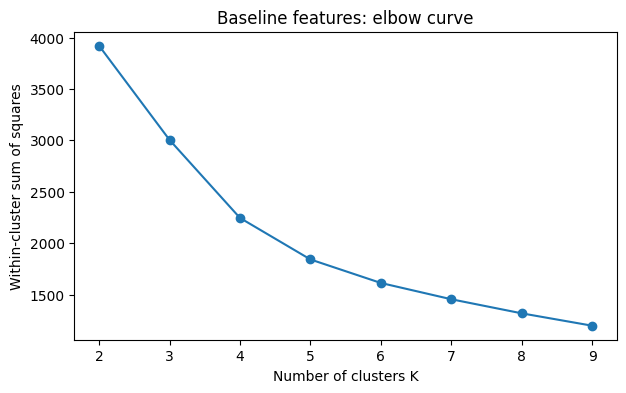

In [7]:
baseline_scores, baseline_k = kmeans_grid(X_baseline)

print("Baseline (5 features) - selected K:", baseline_k)
display(baseline_scores)
plot_selection_scores(baseline_scores, "Baseline features")

## 4. Question 1 - raw, row-standardized and energy-share profiles

The same daily curves can be "similar" in different ways depending on the normalization.

**Raw**: Euclidean distance reacts to level, amplitude, timing and shape all at once.

**Row-standardized**: for day \(i\),

\[
\tilde{x}_{i,t} = \frac{x_{i,t} - \bar{x}_i}{s_i}
\]

This removes the daily level and scale, so only the relative shape of the day matters.

**Energy share**:

\[
p_{i,t} = \frac{x_{i,t}}{\sum_s x_{i,s}}
\]

This removes the total daily consumption and only keeps how it is spread over the 24 hours.

In [8]:

row_mean = X_raw.mean(axis=1, keepdims=True)
row_std = X_raw.std(axis=1, ddof=1, keepdims=True)
assert (row_std > 1e-12).all(), "a day has (almost) zero variance"
X_row_scaled = (X_raw - row_mean) / row_std


daily_total = X_raw.sum(axis=1, keepdims=True)
assert (daily_total > 1e-12).all(), "a day has (almost) zero total consumption"
X_share = X_raw / daily_total

representations = {
    "Raw": X_raw,
    "Row-standardized": X_row_scaled,
    "Energy-share": X_share,
}

for name, X in representations.items():
    print(name, X.shape)

Raw (1358, 24)
Row-standardized (1358, 24)
Energy-share (1358, 24)


## 5. Question 2 - choosing the number of clusters

\(K\) is chosen separately for each representation with the CH criterion. The normalization changes the geometry, so the best \(K\) for raw profiles is not necessarily the best one after removing level and scale.


Raw - selected K = 2


,WSS,BSS,R2,Calinski_Harabasz
K,,,,
2,"15,267.7378","4,521.5725",0.2285,401.5822
3,"13,549.2868","6,240.0235",0.3153,312.0176
4,"12,614.4719","7,174.8385",0.3626,256.7086
5,"11,980.3474","7,808.9629",0.3946,220.4762
6,"11,534.2229","8,255.0874",0.4171,193.5263
7,"11,133.3719","8,655.9385",0.4374,175.0619
8,"10,793.7641","8,995.5462",0.4546,160.7276
9,"10,406.4697","9,382.8406",0.4741,152.0383


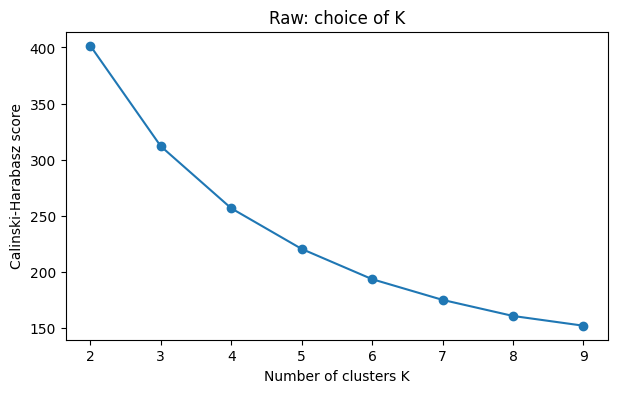

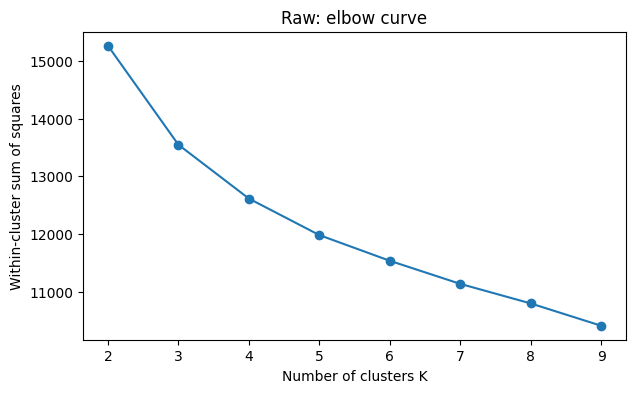


Row-standardized - selected K = 2


,WSS,BSS,R2,Calinski_Harabasz
K,,,,
2,"19,376.5604","2,866.9685",0.1289,200.6346
3,"17,872.6684","4,370.8606",0.1965,165.6864
4,"16,789.6242","5,453.9047",0.2452,146.6101
5,"16,094.9337","6,148.5952",0.2764,129.2184
6,"15,561.9134","6,681.6155",0.3004,116.0981
7,"15,075.1203","7,168.4086",0.3223,107.0696
8,"14,680.3128","7,563.2161",0.3400,99.3589
9,"14,341.5685","7,901.9604",0.3552,92.9095


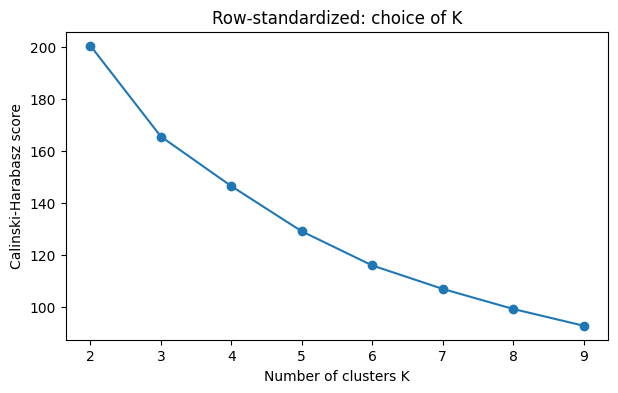

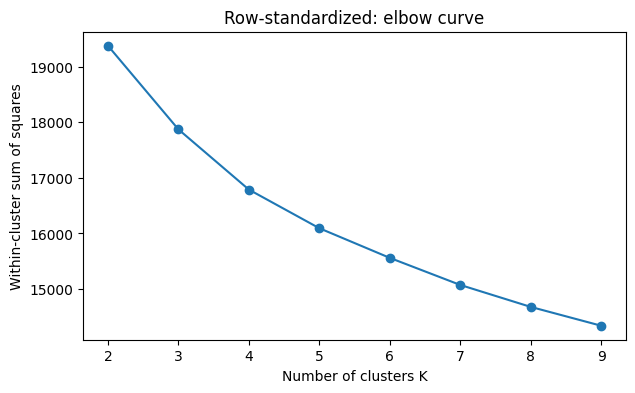


Energy-share - selected K = 2


,WSS,BSS,R2,Calinski_Harabasz
K,,,,
2,17.2707,2.7708,0.1383,217.5503
3,15.9238,4.1178,0.2055,175.1966
4,14.9192,5.1223,0.2556,154.9589
5,14.2495,5.7921,0.2890,137.4905
6,13.7424,6.2992,0.3143,123.9448
7,13.3381,6.7034,0.3345,113.1635
8,12.9824,7.0592,0.3522,104.8658
9,12.6358,7.4058,0.3695,98.8307


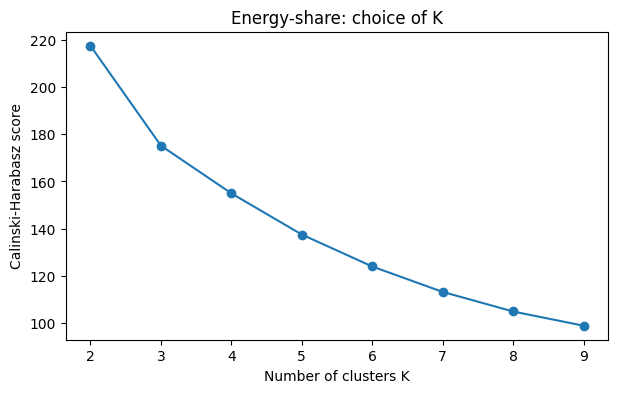

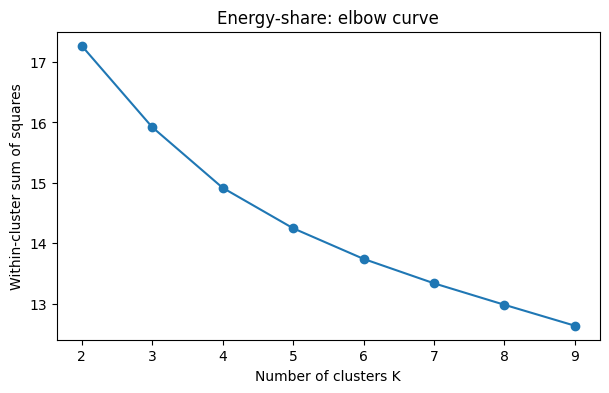


Selected K by representation:


,Selected K
Raw,2
Row-standardized,2
Energy-share,2


In [9]:
best_k = {}
labels_by_rep = {}

for name, X in representations.items():
    scores, best_k[name] = kmeans_grid(X)
    _, labels_by_rep[name] = fit_kmeans(X, best_k[name])

    print(f"\n{name} - selected K = {best_k[name]}")
    display(scores)
    plot_selection_scores(scores, name)

print("\nSelected K by representation:")
display(pd.Series(best_k, name="Selected K").to_frame())

## 6. Question 3 - interpreting and comparing the partitions

There is no true label here, so I interpret the clusters using their mean curves, how spread out they are, their sizes, total consumption, peak hour, and the weekday/weekend and monthly composition.

To compare partitions I use the **Adjusted Rand Index (ARI)**. It does not depend on how clusters are numbered. A high ARI only says that two pipelines group days in a similar way, not that the clustering is good.

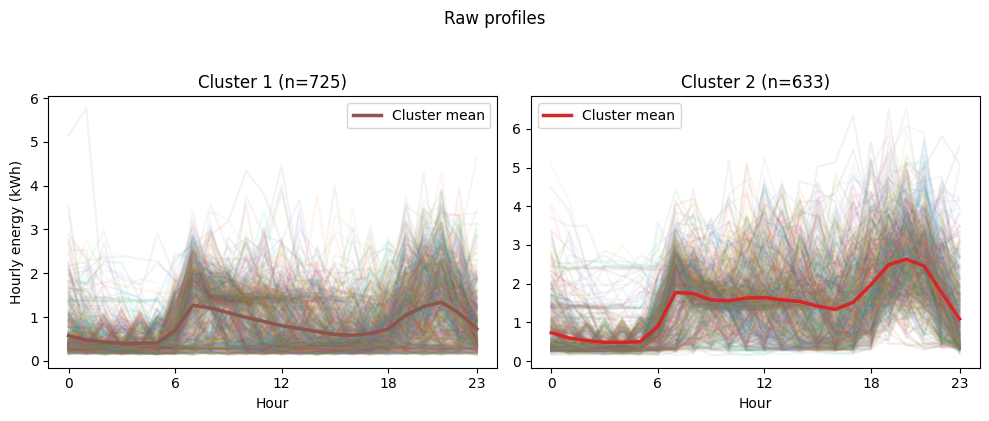


Raw: summary in original units (kWh)


,n_days,mean_hourly_energy,mean_daily_total,peak_hour_of_mean_profile,mean_peak_value,weekend_share
cluster,,,,,,
1,725,0.7925,19.0190,21,1.3403,0.1986
2,633,1.4144,33.9460,20,2.6316,0.3633


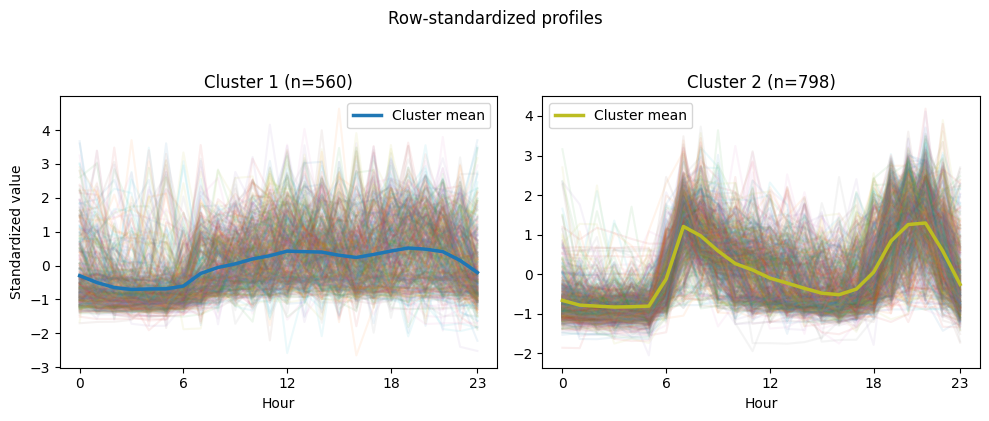


Row-standardized: summary in original units (kWh)


,n_days,mean_hourly_energy,mean_daily_total,peak_hour_of_mean_profile,mean_peak_value,weekend_share
cluster,,,,,,
1,560,1.1317,27.1599,19,1.6785,0.5321
2,798,1.0478,25.1467,21,2.0717,0.0952


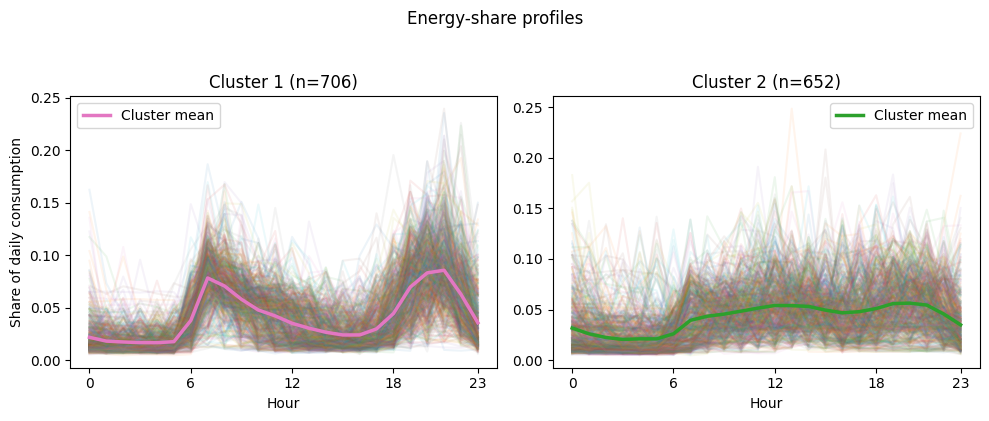


Energy-share: summary in original units (kWh)


,n_days,mean_hourly_energy,mean_daily_total,peak_hour_of_mean_profile,mean_peak_value,weekend_share
cluster,,,,,,
1,706,1.0310,24.7448,21,2.1254,0.0992
2,652,1.1380,27.3110,20,1.6505,0.4663


In [10]:
plot_info = {
    "Raw": (X_raw, "Hourly energy (kWh)"),
    "Row-standardized": (X_row_scaled, "Standardized value"),
    "Energy-share": (X_share, "Share of daily consumption"),
}

for name, labels in labels_by_rep.items():
    X_plot, ylabel = plot_info[name]
    plot_cluster_profiles(X_plot, labels, f"{name} profiles", y_label=ylabel)

    print(f"\n{name}: summary in original units (kWh)")
    display(cluster_summary(X_raw, labels, dates))

,Raw,Row-standardized,Energy-share
Raw,1.0000,0.0152,0.0176
Row-standardized,0.0152,1.0000,0.6824
Energy-share,0.0176,0.6824,1.0000


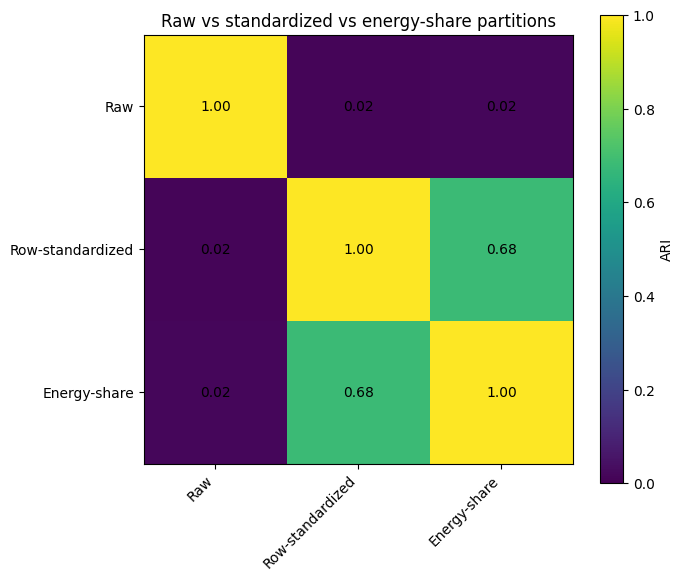

In [11]:
ari_rep = ari_matrix(labels_by_rep)
display(ari_rep)
plot_ari_heatmap(ari_rep, "Raw vs standardized vs energy-share partitions")

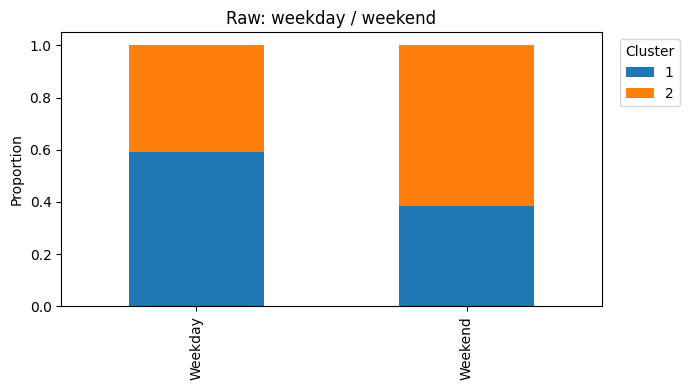

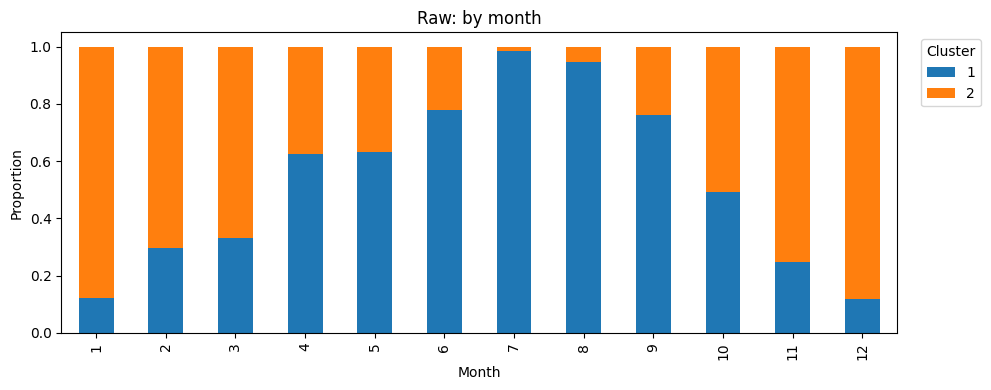

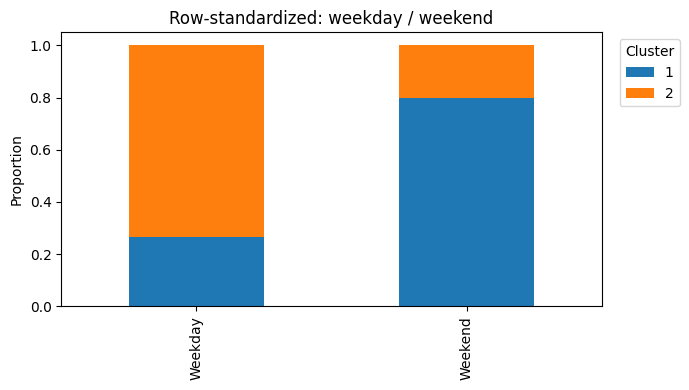

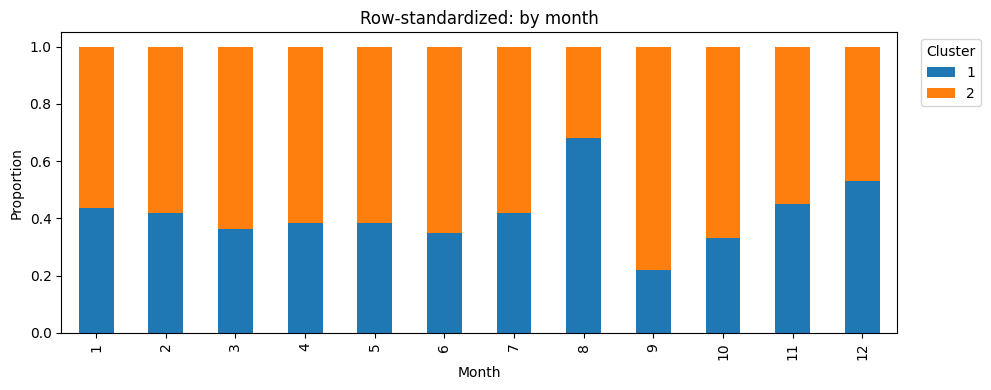

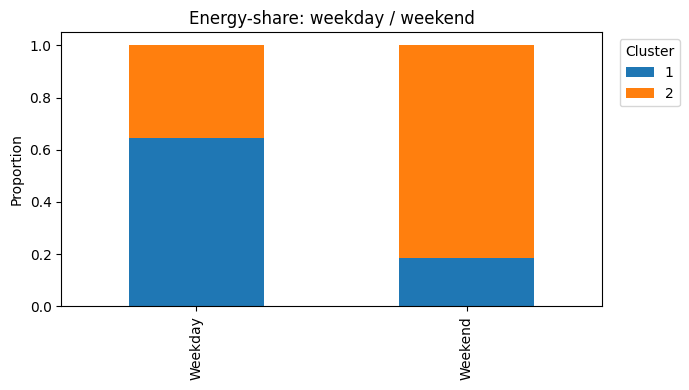

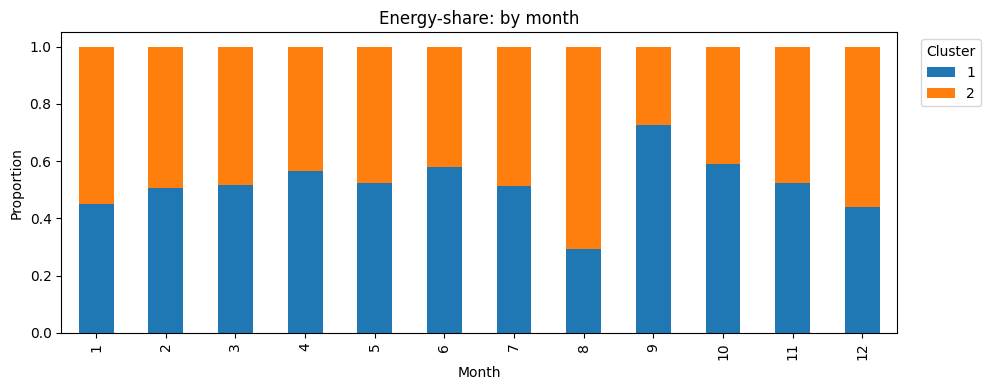

In [12]:
def plot_calendar_composition(labels, dates, title):
    dates = pd.DatetimeIndex(dates)
    cal = pd.DataFrame({
        "cluster": labels + 1,
        "month": dates.month,
        "day_type": np.where(dates.dayofweek < 5, "Weekday", "Weekend"),
    })

    by_day_type = pd.crosstab(cal["day_type"], cal["cluster"], normalize="index")
    by_day_type.plot(kind="bar", stacked=True, figsize=(7, 4))
    plt.ylabel("Proportion")
    plt.xlabel("")
    plt.title(f"{title}: weekday / weekend")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    by_month = pd.crosstab(cal["month"], cal["cluster"], normalize="index")
    by_month.plot(kind="bar", stacked=True, figsize=(10, 4))
    plt.ylabel("Proportion")
    plt.xlabel("Month")
    plt.title(f"{title}: by month")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


for name, labels in labels_by_rep.items():
    plot_calendar_composition(labels, dates, name)

## 7. Question 4 - Gaussian kernel k-means

The Gaussian kernel defines a similarity

\[
k_\sigma(x_i,x_j) = \exp\left(-\frac{\|x_i-x_j\|^2}{2\sigma^2}\right)
\]

The bandwidth \(\sigma\) controls the geometry: a small \(\sigma\) makes similarity very local, a large one makes it much broader.

In the course, the reference bandwidth is the **median pairwise Euclidean distance**. I also try half and twice that value to see how sensitive the result is. Kernel k-means is coded directly from the Gram matrix, without building the feature space.

In [13]:
def rbf_kernel(D2, sigma):
    return np.exp(-D2 / (2 * sigma ** 2))


def kernel_distances(K, labels, n_clusters):
    """Squared distance (in feature space) from each point to each cluster centroid."""
    Z = np.eye(n_clusters)[labels]        # one-hot membership, n x k
    sizes = Z.sum(axis=0)
    cross = K @ Z                         # sum of K(i, j) over j in cluster c
    within = (Z * cross).sum(axis=0)      # sum of K(i, j) over i, j in cluster c

    with np.errstate(divide="ignore", invalid="ignore"):
        d = np.diag(K)[:, None] - 2 * cross / sizes + within / sizes ** 2
    d[:, sizes == 0] = np.inf             # empty cluster
    return d


def kernel_kmeans(K, n_clusters, n_init=5, max_iter=100):
    n = K.shape[0]
    rng = np.random.default_rng(SEED)
    best_labels, best_obj = None, np.inf

    for _ in range(n_init):
        
        labels = rng.integers(0, n_clusters, size=n)
        labels[rng.choice(n, n_clusters, replace=False)] = np.arange(n_clusters)

        for _ in range(max_iter):
            d = kernel_distances(K, labels, n_clusters)
            new_labels = d.argmin(axis=1)

            
            empty = np.where(np.bincount(new_labels, minlength=n_clusters) == 0)[0]
            if len(empty) > 0:
                worst = np.argsort(d[np.arange(n), new_labels])[::-1]
                new_labels[worst[:len(empty)]] = empty

            if np.array_equal(new_labels, labels):
                break
            labels = new_labels

        d = kernel_distances(K, labels, n_clusters)
        obj = d[np.arange(n), labels].sum()
        if obj < best_obj:
            best_obj, best_labels = obj, labels.copy()

    return best_labels, best_obj


def kernel_representatives(K, labels):
    """For each cluster, the observed day closest to the kernel centroid."""
    d = kernel_distances(K, labels, labels.max() + 1)
    reps = {}
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        reps[c] = idx[np.argmin(d[idx, c])]
    return reps

In [14]:
D2_raw = pairwise_distances(X_raw, metric="sqeuclidean")
sigma_ref = np.sqrt(np.median(D2_raw[np.triu_indices_from(D2_raw, k=1)]))

bandwidths = {
    "0.5 × median distance": 0.5 * sigma_ref,
    "1.0 × median distance": sigma_ref,
    "2.0 × median distance": 2.0 * sigma_ref,
}


K_KERNEL = best_k["Raw"]
print(f"Reference bandwidth: {sigma_ref:.4f}")
print("K:", K_KERNEL)

kernel_labels, kernel_obj, kernel_mats = {}, {}, {}

for bw_name, sigma in bandwidths.items():
    print(f"\n{bw_name} (sigma = {sigma:.4f})")
    K = rbf_kernel(D2_raw, sigma)
    labels, obj = kernel_kmeans(K, K_KERNEL)

    kernel_mats[bw_name] = K
    kernel_labels[bw_name] = labels
    kernel_obj[bw_name] = obj

    print("Cluster sizes:", np.bincount(labels))
    print("Objective:", f"{obj:.4f}")

display(pd.Series(kernel_obj, name="Kernel objective").to_frame())

Reference bandwidth: 4.8731
K: 2

0.5 × median distance (sigma = 2.4365)
Cluster sizes: [460 898]
Objective: 1012.7555

1.0 × median distance (sigma = 4.8731)
Cluster sizes: [617 741]
Objective: 472.5121

2.0 × median distance (sigma = 9.7462)
Cluster sizes: [658 700]
Objective: 147.7408


,Kernel objective
0.5 × median distance,"1,012.7555"
1.0 × median distance,472.5121
2.0 × median distance,147.7408


,0.5 × median distance,1.0 × median distance,2.0 × median distance
0.5 × median distance,1.0000,0.5904,0.5014
1.0 × median distance,0.5904,1.0000,0.8828
2.0 × median distance,0.5014,0.8828,1.0000


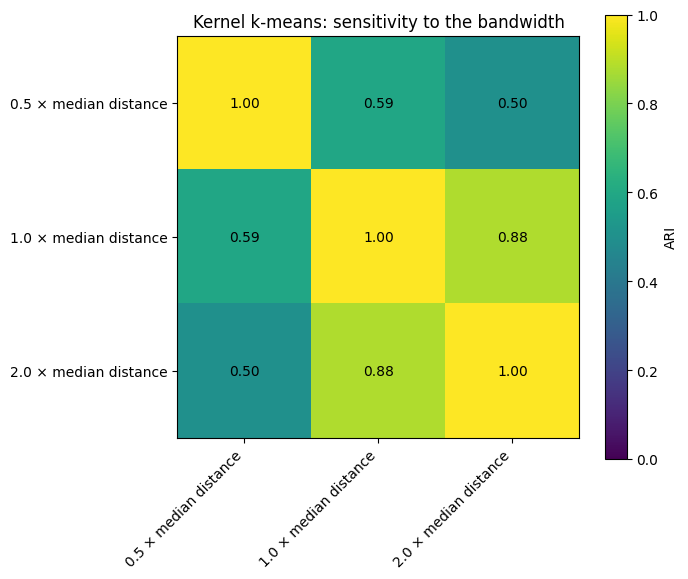

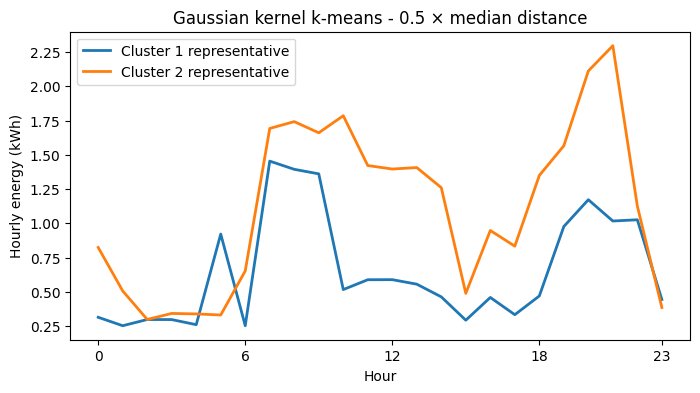

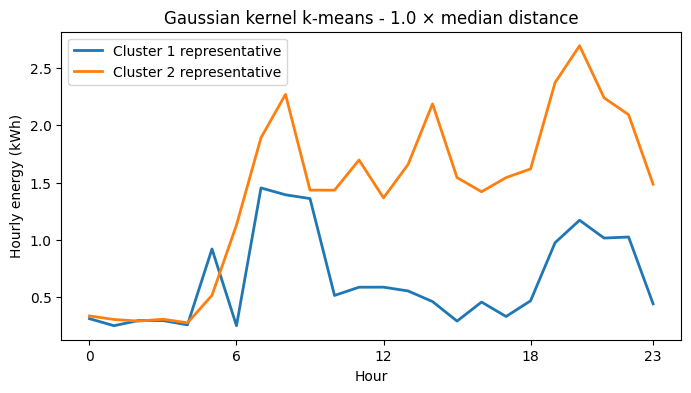

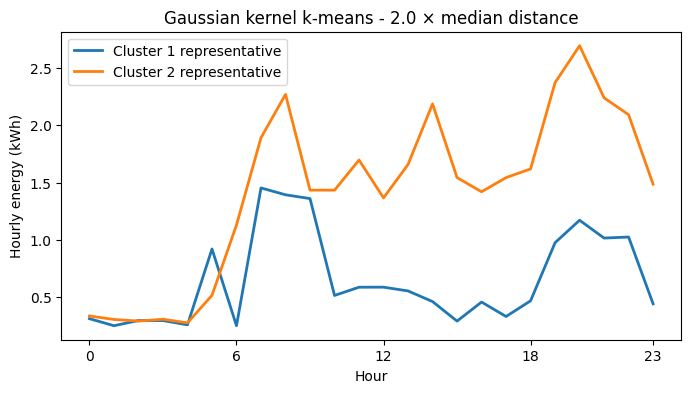

In [15]:
kernel_ari = ari_matrix(kernel_labels)
display(kernel_ari)
plot_ari_heatmap(kernel_ari, "Kernel k-means: sensitivity to the bandwidth")

for bw_name, labels in kernel_labels.items():
    reps = kernel_representatives(kernel_mats[bw_name], labels)

    plt.figure(figsize=(8, 4))
    for c, i in reps.items():
        plt.plot(X_raw[i], linewidth=2, label=f"Cluster {c + 1} representative")
    plt.xticks([0, 6, 12, 18, 23])
    plt.xlabel("Hour")
    plt.ylabel("Hourly energy (kWh)")
    plt.title(f"Gaussian kernel k-means - {bw_name}")
    plt.legend()
    plt.show()

### Reading the bandwidth experiment

The kernel objective cannot be compared with the WSS of ordinary k-means, since the geometries are different. What I look at instead is:

- how the cluster sizes change with \(\sigma\);
- whether the representative curves change;
- the ARI between bandwidths;
- whether the weekday/month composition stays stable.

If the partition changes a lot with \(\sigma\), then the choice of similarity is a real modelling decision and not a detail.

## 8. Question 5 - time-series features

I extend the five baseline features with some that take the order of the hours into account:

| Feature | What it captures |
|---|---|
| Mean hourly energy | overall level |
| Standard deviation | variability within the day |
| Lag-1 autocorrelation | dependence between consecutive hours |
| Morning share | share of consumption between 06:00 and 10:00 |
| Evening share | share of consumption between 18:00 and 23:00 |
| Mean absolute increment | hour-to-hour fluctuations |

This is much smaller than the 24-dimensional curve and easier to interpret, but it only keeps what the features explicitly encode.

In [16]:
def lag1_autocorrelation(x):
    xc = x - x.mean()
    denom = np.sum(xc ** 2)
    if denom <= 1e-12:
        return 0.0
    return np.sum(xc[1:] * xc[:-1]) / denom


def extract_features(X, index):
    total = X.sum(axis=1)
    return pd.DataFrame({
        "mean_hourly_energy": X.mean(axis=1),
        "std_hourly_energy": X.std(axis=1, ddof=1),
        "lag1_autocorrelation": [lag1_autocorrelation(row) for row in X],
        "morning_energy_share": X[:, 6:10].sum(axis=1) / total,
        "evening_energy_share": X[:, 18:24].sum(axis=1) / total,
        "mean_absolute_increment": np.abs(np.diff(X, axis=1)).mean(axis=1),
    }, index=index)


ts_features = extract_features(X_raw, dates)
X_features = StandardScaler().fit_transform(ts_features)

display(ts_features.describe().T)

,count,mean,std,min,25%,50%,75%,max
mean_hourly_energy,"1,358.0000",1.0824,0.4136,0.1738,0.8097,1.0658,1.3106,3.3149
std_hourly_energy,"1,358.0000",0.7539,0.2860,0.0197,0.5834,0.7494,0.9123,1.7581
lag1_autocorrelation,"1,358.0000",0.5403,0.2155,-0.7904,0.4786,0.5867,0.6701,0.8826
morning_energy_share,"1,358.0000",0.2018,0.0763,0.0328,0.1422,0.2090,0.2536,0.4988
evening_energy_share,"1,358.0000",0.3420,0.0998,0.0542,0.2753,0.3384,0.4090,0.6852
mean_absolute_increment,"1,358.0000",0.4398,0.1605,0.0228,0.3398,0.4399,0.5382,1.0093


Selected K (engineered features): 2


,WSS,BSS,R2,Calinski_Harabasz
K,,,,
2,"5,611.6031","2,536.3969",0.3113,612.9070
3,"4,370.7134","3,777.2866",0.4636,585.5135
4,"3,804.7751","4,343.2249",0.5330,515.2058
5,"3,382.7030","4,765.2970",0.5848,476.5011
6,"3,065.8557","5,082.1443",0.6237,448.2311
7,"2,855.2103","5,292.7897",0.6496,417.4025
8,"2,654.2443","5,493.7557",0.6742,399.1758
9,"2,475.0505","5,672.9495",0.6962,386.4976


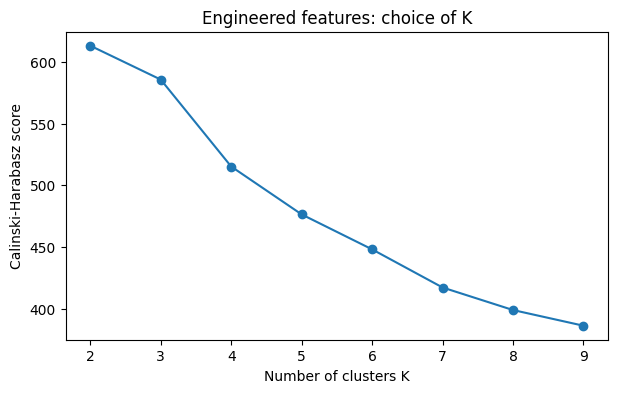

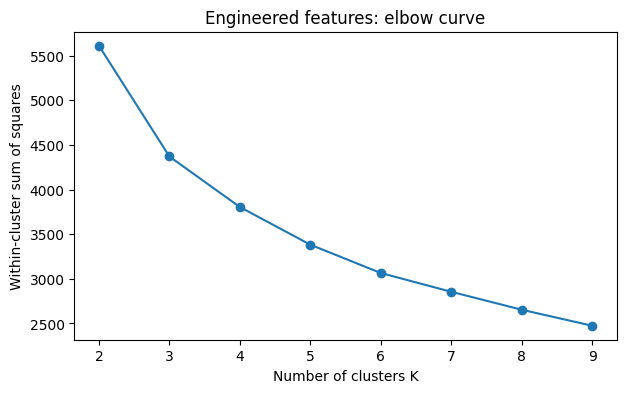

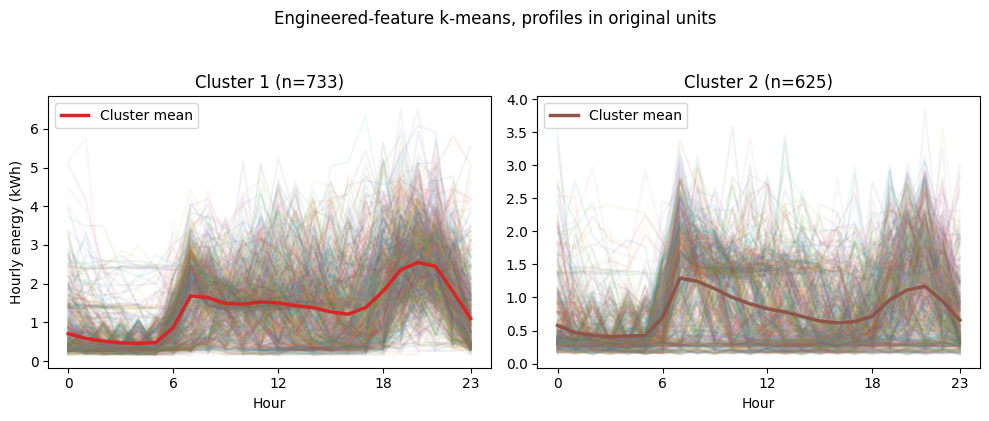

,n_days,mean_hourly_energy,mean_daily_total,peak_hour_of_mean_profile,mean_peak_value,weekend_share
cluster,,,,,,
1,733,1.3386,32.1269,20,2.5477,0.3479
2,625,0.7818,18.7641,7,1.2921,0.1904


In [17]:
feature_scores, feature_k = kmeans_grid(X_features)
_, feature_labels = fit_kmeans(X_features, feature_k)

print("Selected K (engineered features):", feature_k)
display(feature_scores)
plot_selection_scores(feature_scores, "Engineered features")

plot_cluster_profiles(X_raw, feature_labels, "Engineered-feature k-means, profiles in original units")
display(cluster_summary(X_raw, feature_labels, dates))

### PCA to help interpretation

PCA is applied to the standardized features, only to visualise them. The clustering itself still uses all six features. The first two components give a 2D picture and show which features drive the main directions of variation.

,Explained variance ratio
PC1,0.5323
PC2,0.1732
PC3,0.1478
PC4,0.1023
PC5,0.0306
PC6,0.0139


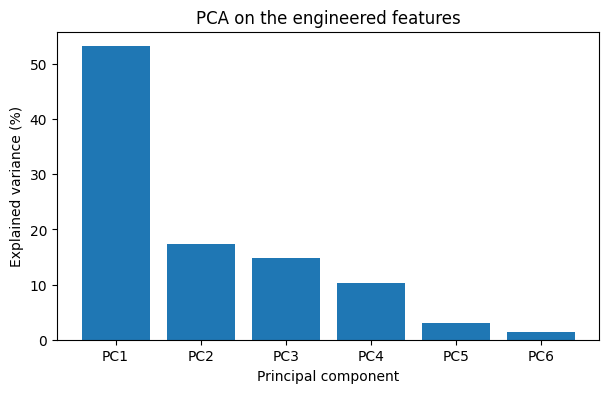

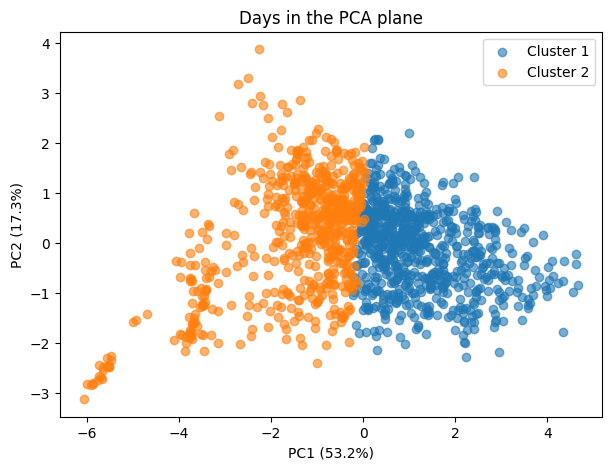

,PC1,PC2
mean_hourly_energy,0.4925,-0.0437
std_hourly_energy,0.5401,0.0230
lag1_autocorrelation,0.3651,0.4677
morning_energy_share,-0.1516,0.8761
evening_energy_share,0.2752,0.0550
mean_absolute_increment,0.4834,-0.0909


In [18]:
pca = PCA()
pcs = pca.fit_transform(X_features)
pc_names = [f"PC{i + 1}" for i in range(X_features.shape[1])]

explained = pd.Series(pca.explained_variance_ratio_, index=pc_names, name="Explained variance ratio")
display(explained.to_frame())

plt.figure(figsize=(7, 4))
plt.bar(explained.index, 100 * explained.values)
plt.ylabel("Explained variance (%)")
plt.xlabel("Principal component")
plt.title("PCA on the engineered features")
plt.show()

plt.figure(figsize=(7, 5))
for c in np.unique(feature_labels):
    m = feature_labels == c
    plt.scatter(pcs[m, 0], pcs[m, 1], alpha=0.6, label=f"Cluster {c + 1}")
plt.xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}%)")
plt.ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}%)")
plt.title("Days in the PCA plane")
plt.legend()
plt.show()

loadings = pd.DataFrame(pca.components_.T, index=ts_features.columns, columns=pc_names)
display(loadings[["PC1", "PC2"]])

## 9. Comparing all the pipelines

Here I compare the partitions themselves (not the objective values). Each pipeline has its own idea of similarity:

- **Raw k-means**: level + amplitude + timing + shape;
- **Row-standardized**: relative shape of the day;
- **Energy-share**: how the daily total is spread over the hours;
- **Engineered features**: a few interpretable summaries;
- **Gaussian kernel**: nonlinear similarity on the raw curves.

ARI tells us whether two choices give similar groupings, but it can't rank them by quality.

,Raw,Row-standardized,Energy-share,Engineered features,Gaussian kernel
Raw,1.0000,0.0152,0.0176,0.5311,0.7070
Row-standardized,0.0152,1.0000,0.6824,0.0041,0.0013
Energy-share,0.0176,0.6824,1.0000,0.0003,0.0066
Engineered features,0.5311,0.0041,0.0003,1.0000,0.5839
Gaussian kernel,0.7070,0.0013,0.0066,0.5839,1.0000


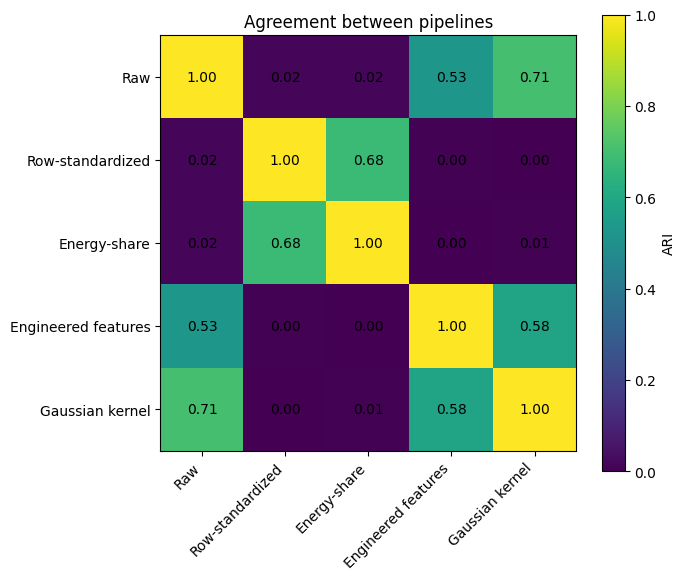

In [19]:
all_partitions = {
    "Raw": labels_by_rep["Raw"],
    "Row-standardized": labels_by_rep["Row-standardized"],
    "Energy-share": labels_by_rep["Energy-share"],
    "Engineered features": feature_labels,
    "Gaussian kernel": kernel_labels["1.0 × median distance"],
}

all_ari = ari_matrix(all_partitions)
display(all_ari)
plot_ari_heatmap(all_ari, "Agreement between pipelines")

## 10. Question 6 - conclusion

The main thing I take from this work is that **clustering time series cannot be separated from the representation that defines similarity**.

The same set of daily curves gives different, equally useful partitions depending on the preprocessing, because each one answers a different question:

- raw profiles keep level, amplitude, timing and shape;
- row standardization removes level and scale;
- energy shares remove the total and keep how consumption is distributed over the day;
- features compress a curve into a few chosen summaries;
- the Gaussian kernel changes the geometry and can capture nonlinear similarity.

So when two partitions disagree, it doesn't mean one of them failed; they may just be looking at different aspects of the data.

For a solid analysis I would combine:

1. checking data quality before modelling;
2. deciding which differences should matter for the question asked;
3. an internal criterion to choose \(K\) inside a given representation;
4. representative curves and within-cluster spread;
5. calendar information to describe the clusters;
6. ARI to measure agreement between choices;
7. a sensitivity analysis on key hyperparameters such as the bandwidth.

In the end, the representation should be chosen because it fits the question, not because it gives the best value of some clustering criterion.